# Part E: Hardware comparison

All rows are CORE runs from `results/timings.csv`. Before-fix hashes: `2c52c55`, `e9c1863`, `e9db2d1`. After-fix hashes (all four fixes, identical `indexes/` code): `9aba440`, `65bfead`, `65c95ad`. Vicente's partial run at `c8ec36c` (no AVL fix) is excluded. Q5 uses E1 `memory_bytes` from neil-mac on the final commit (`5b5a8da`), because CORE does not record memory.

## Setup

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

df = pd.read_csv("../results/timings.csv")
core = df[df['experiment'] == 'CORE'].copy()
core['ns_per_op'] = core['total_ns'] / core['n_ops']

before_hashes = ["2c52c55", "e9c1863", "e9db2d1"]
after_hashes  = ["9aba440", "65bfead", "65c95ad"]

# drop Vicente's partial run (had 3 of 4 fixes)
core = core[~((core['machine_id'] == 'vicente-mba') & (core['code_version'] == 'c8ec36c'))]

core['phase'] = np.where(core['code_version'].isin(after_hashes), 'after', 'before')
print(core.groupby(['machine_id', 'phase'])['code_version'].unique())

machine_id   phase 
chloe-mac    after     [9aba440]
             before    [e9c1863]
kenza-mba    after     [65bfead]
             before    [2c52c55]
neil-mac     after     [65c95ad]
             before    [e9c1863]
vicente-mba  after     [65bfead]
             before    [e9db2d1]
Name: code_version, dtype: object


## Q1: Are the counters identical across machines?

In [2]:
counters = ['comparisons', 'nodes_visited', 'rotations', 'splits', 'resizes']
keys = ['phase', 'index_type', 'operation', 'n_keys']

# across all machines and all reps, each counter should have exactly one value
nuniq = core.groupby(keys)[counters].nunique()
print("configurations with differing counters:", (nuniq > 1).any(axis=1).sum())

# before vs after comparisons per op at full size, to show where the fixes changed the work
full = core[core['n_keys'] == 114000]
cmp = (full['comparisons'] / full['n_ops']).groupby(
    [full['index_type'], full['operation'], full['phase']]).median().unstack('phase')
display(cmp.round(1))

configurations with differing counters: 0


phase                        after    before
index_type    operation                     
avl_tree      build           15.3      16.5
              point_hit       15.7      16.8
              point_miss      16.1      18.0
              range          470.7     471.6
bplus_tree    build           15.4      15.4
              point_hit       16.8      16.8
              point_miss      15.3      15.3
              range          473.7   45653.0
hash_table    build            0.7       0.9
              point_hit        1.3       1.4
              point_miss       0.7       0.8
              range        45653.0   45653.0
ref_bisect    build            NaN       NaN
              point_hit        NaN       NaN
              point_miss       NaN       NaN
              range            NaN       NaN
ref_dict      build            NaN       NaN
              point_hit        NaN       NaN
              point_miss       NaN       NaN
              range            NaN       NaN
sorted_list   build           15.2      15.2
              point_hit       16.5   45613.6
              point_miss      16.1   83524.4
              range          473.6     473.6
unsorted_list build            0.0       0.0
              point_hit   114000.0  114000.0
              point_miss  114000.0  114000.0
              range       114000.0  114000.0

**Answer:** Yes. 0 configurations have differing counters: within each phase, every machine and every rep produced exactly the same comparisons, nodes visited, rotations, splits and resizes. Counters change only between phases, and only where we fixed code: sorted list point lookups (45,614 → 16.5 comparisons per hit), B+ tree range (45,653 → 474 per query), AVL tree (fewer comparisons per insert and lookup after the rotation fix) and hash table (fewer comparisons per build and lookup after the resize fix). The reference indexes don't count operations, so they show NaN.

## Q2: How much faster is the fastest machine than the slowest?

In [3]:
after = core[core['phase'] == 'after']

med = after.groupby(['index_type', 'operation', 'n_keys', 'machine_id'])['ns_per_op'] \
           .median().unstack('machine_id')
ratio = med.max(axis=1) / med.min(axis=1)

summary = med.copy()
summary['fastest'] = med.idxmin(axis=1)
summary['slowest'] = med.idxmax(axis=1)
summary['ratio'] = ratio.round(2)
display(summary)
print(ratio.describe().round(2))

machine_id                            chloe-mac     kenza-mba      neil-mac  \
index_type    operation  n_keys                                               
avl_tree      build      10000.0   3.016588e+03  4.368363e+03  4.854837e+03   
                         114000.0  3.811840e+03  5.589708e+03  5.855222e+03   
              point_hit  114000.0  9.764580e+02  1.440542e+03  1.249666e+03   
              point_miss 114000.0  5.992090e+02  9.505410e+02  7.927920e+02   
              prefix     113999.0  3.800854e+04  5.743250e+04  4.674208e+04   
              range      114000.0  8.417312e+04  1.253619e+05  1.189821e+05   
bplus_tree    build      10000.0   1.018650e+03  1.522312e+03  1.416442e+03   
                         114000.0  1.366176e+03  1.985933e+03  1.969016e+03   
              point_hit  114000.0  1.670334e+03  2.354167e+03  2.002458e+03   
              point_miss 114000.0  1.058667e+03  1.460083e+03  1.291125e+03   
              prefix     113999.0  2.039000e+04  2.870938e+04  2.598312e+04   
              range      114000.0  4.808104e+04  6.173625e+04  5.999250e+04   
hash_table    build      10000.0   4.664916e+02  6.602167e+02  6.537333e+02   
                         114000.0  5.604240e+02  8.058823e+02  7.920406e+02   
              point_hit  114000.0  5.673750e+02  7.942910e+02  7.490830e+02   
              point_miss 114000.0  4.073340e+02  5.896250e+02  4.581670e+02   
              prefix     113999.0  6.781878e+06  1.129408e+07  8.993717e+06   
              range      114000.0  1.840098e+06  2.862657e+06  2.962142e+06   
ref_bisect    build      10000.0   8.620875e+02  1.171433e+03  1.048333e+03   
                         114000.0  5.730453e+03  8.151053e+03  7.734230e+03   
              point_hit  114000.0  5.877500e+02  1.002417e+03  7.402090e+02   
              point_miss 114000.0  2.124580e+02  3.735840e+02  2.541670e+02   
              prefix     113999.0  7.363955e+03  9.405835e+03  7.976250e+03   
              range      114000.0  1.437646e+04  1.782833e+04  1.698958e+04   
ref_dict      build      10000.0   9.722920e+01  1.370792e+02  1.319708e+02   
                         114000.0  1.311053e+02  1.842708e+02  1.518289e+02   
              point_hit  114000.0  2.592910e+02  3.663750e+02  2.717910e+02   
              point_miss 114000.0  1.702910e+02  2.300000e+02  1.816670e+02   
              prefix     113999.0  1.687932e+06  2.518108e+06  2.456805e+06   
              range      114000.0  8.026252e+05  1.168481e+06  1.185411e+06   
sorted_list   build      10000.0   1.394204e+03  1.943325e+03  2.092279e+03   
                         114000.0  6.492342e+03  9.284572e+03  9.464526e+03   
              point_hit  114000.0  1.597917e+03  2.534292e+03  1.976459e+03   
              point_miss 114000.0  9.419590e+02  1.651750e+03  1.150833e+03   
              prefix     113999.0  2.183104e+04  2.920458e+04  2.378562e+04   
              range      114000.0  4.114104e+04  5.222125e+04  5.305104e+04   
unsorted_list build      10000.0   7.742920e+01  9.108750e+01  9.758340e+01   
                         114000.0  7.025511e+01  8.525511e+01  1.011309e+02   
              point_hit  114000.0  1.452308e+06  3.000598e+06  3.214632e+06   
              point_miss 114000.0  1.580386e+06  2.967147e+06  3.374016e+06   
              prefix     113999.0  2.596792e+06  3.462162e+06  4.451126e+06   
              range      114000.0  1.794134e+06  2.662040e+06  3.240478e+06   

machine_id                          vicente-mba    fastest      slowest  ratio  
index_type    operation  n_keys                                                 
avl_tree      build      10000.0   9.243408e+03  chloe-mac  vicente-mba   3.06  
                         114000.0  1.764331e+04  chloe-mac  vicente-mba   4.63  
              point_hit  114000.0  1.926333e+04  chloe-mac  vicente-mba  19.73  
              point_miss 114000.0  2.013500e+03  chloe-mac  vicente-mba   3.36  
              prefix     113999.0  1.

count    42.00
mean      3.76
std       2.83
min       1.72
25%       2.58
50%       3.18
75%       4.09
max      19.73
dtype: float64


**Answer:** chloe-mac (M5) is the fastest and vicente-mba (M1) the slowest in all 42 configurations. The median fastest-to-slowest ratio is 3.2× (range 1.7× to 19.7×). The ratio is not constant: the C reference indexes have a median of 2.5× and the Python indexes 3.3×, and the largest ratios (AVL point hits 19.7×, B+ tree build 8.4×, B+ tree misses 6.6×) come from Vicente's run, which is much noisier than the others (see Q4). Leaving vicente-mba out, the other three machines differ by only 1.2× to 2.2× (median 1.46×).

## Figure: point hits by machine (after fixes)

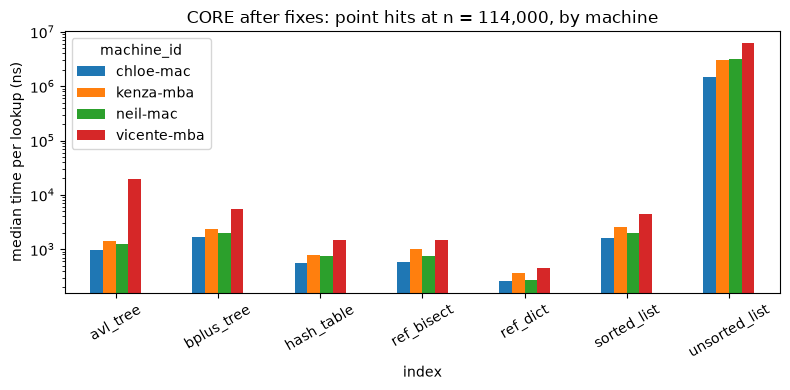

In [8]:
hits = med.xs(('point_hit', 114000), level=['operation', 'n_keys'])
hits.plot(kind='bar', logy=True, figsize=(8, 4))
plt.ylabel('median time per lookup (ns)')
plt.xlabel('index')
plt.title('CORE after fixes: point hits at n = 114,000, by machine')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('hardware_point_hits.png', dpi=150)
plt.show()

**Figure caption:** median time per point hit (ns, log scale) at n = 114,000 for each index on each machine, CORE after fixes. The bars keep the same order on every machine and differ mainly by a constant factor, with chloe-mac lowest and vicente-mba highest. The AVL bar for vicente-mba is a noise spike, not a real difference.

## Q3: Does the ranking of the indexes change between machines?

In [5]:
# rank indexes (1 = fastest) within each operation, separately for each machine
rank = med.groupby(level=['operation', 'n_keys']).rank()
display(rank)

differs = rank.nunique(axis=1) > 1
print("rows where machines disagree on rank:")
display(rank[differs])

machine_id                         chloe-mac  kenza-mba  neil-mac  vicente-mba
index_type    operation  n_keys                                               
avl_tree      build      10000.0         7.0        7.0       7.0          7.0
                         114000.0        5.0        5.0       5.0          6.0
              point_hit  114000.0        4.0        4.0       4.0          6.0
              point_miss 114000.0        4.0        4.0       4.0          4.0
              prefix     113999.0        4.0        4.0       4.0          4.0
              range      114000.0        4.0        4.0       4.0          4.0
bplus_tree    build      10000.0         5.0        5.0       5.0          5.0
                         114000.0        4.0        4.0       4.0          4.0
              point_hit  114000.0        6.0        5.0       6.0          5.0
              point_miss 114000.0        6.0        5.0       6.0          6.0
              prefix     113999.0        2.0        2.0       3.0          3.0
              range      114000.0        3.0        3.0       3.0          3.0
hash_table    build      10000.0         3.0        3.0       3.0          3.0
                         114000.0        3.0        3.0       3.0          3.0
              point_hit  114000.0        2.0        2.0       3.0          3.0
              point_miss 114000.0        3.0        3.0       3.0          3.0
              prefix     113999.0        7.0        7.0       7.0          7.0
              range      114000.0        7.0        7.0       6.0          7.0
ref_bisect    build      10000.0         4.0        4.0       4.0          4.0
                         114000.0        6.0        6.0       6.0          5.0
              point_hit  114000.0        3.0        3.0       2.0          2.0
              point_miss 114000.0        2.0        2.0       2.0          2.0
              prefix     113999.0        1.0        1.0       1.0          1.0
              range      114000.0        1.0        1.0       1.0          1.0
ref_dict      build      10000.0         2.0        2.0       2.0          2.0
                         114000.0        2.0        2.0       2.0          2.0
              point_hit  114000.0        1.0        1.0       1.0          1.0
              point_miss 114000.0        1.0        1.0       1.0          1.0
              prefix     113999.0        5.0        5.0       5.0          5.0
              range      114000.0        5.0        5.0       5.0          5.0
sorted_list   build      10000.0         6.0        6.0       6.0          6.0
                         114000.0        7.0        7.0       7.0          7.0
              point_hit  114000.0        5.0        6.0       5.0          4.0
              point_miss 114000.0        5.0        6.0       5.0          5.0
              prefix     113999.0        3.0        3.0       2.0          2.0
              range      114000.0        2.0        2.0       2.0          2.0
unsorted_list build      10000.0         1.0        1.0       1.0          1.0
                         114000.0        1.0        1.0       1.0          1.0
              point_hit  114000.0        7.0        7.0       7.0          7.0
              point_miss 114000.0        7.0        7.0       7.0          7.0
              prefix     113999.0        6.0        6.0       6.0          6.0
              range      114000.0        6.0        6.0       7.0          6.0

rows where machines disagree on rank:


machine_id                         chloe-mac  kenza-mba  neil-mac  vicente-mba
index_type    operation  n_keys                                               
avl_tree      build      114000.0        5.0        5.0       5.0          6.0
              point_hit  114000.0        4.0        4.0       4.0          6.0
bplus_tree    point_hit  114000.0        6.0        5.0       6.0          5.0
              point_miss 114000.0        6.0        5.0       6.0          6.0
              prefix     113999.0        2.0        2.0       3.0          3.0
hash_table    point_hit  114000.0        2.0        2.0       3.0          3.0
              range      114000.0        7.0        7.0       6.0          7.0
ref_bisect    build      114000.0        6.0        6.0       6.0          5.0
              point_hit  114000.0        3.0        3.0       2.0          2.0
sorted_list   point_hit  114000.0        5.0        6.0       5.0          4.0
              point_miss 114000.0        5.0        6.0       5.0          5.0
              prefix     113999.0        3.0        3.0       2.0          2.0
unsorted_list range      114000.0        6.0        6.0       7.0          6.0

**Answer:** Mostly no. In 29 of 42 configurations all four machines rank the indexes identically, including the top and bottom of every operation (`ref_dict` fastest for point lookups, `ref_bisect` fastest for range and prefix, `unsorted_list` fastest to build and slowest for point lookups). The 13 disagreements are swaps between neighbouring indexes whose times are close, e.g. `hash_table` vs `ref_bisect` on point hits or `bplus_tree` vs `sorted_list` on prefix, plus vicente-mba's noisy AVL rows. None would change a recommendation.

## Q4: How noisy is each machine?

In [6]:
cv = core.groupby(['phase', 'machine_id', 'index_type', 'operation', 'n_keys'])['ns_per_op'] \
         .agg(lambda x: x.std() / x.mean())
display(cv.groupby(['phase', 'machine_id']).agg(['median', 'max']).round(3))

median    max
phase  machine_id                
after  chloe-mac     0.033  0.758
       kenza-mba     0.023  0.230
       neil-mac      0.059  0.971
       vicente-mba   0.147  1.556
before chloe-mac     0.018  0.327
       kenza-mba     0.035  0.212
       neil-mac      0.069  0.353
       vicente-mba   0.035  1.158

**Answer:** We measured noise as the coefficient of variation (standard deviation / mean) of the 5 reps. kenza-mba, the only machine plugged in, was the steadiest after the fixes (median CV 0.023). chloe-mac (0.033) and neil-mac (0.059) were somewhat noisier, and vicente-mba was by far the noisiest after the fixes (median 0.147, max 1.56), even though his before-fix run was steady (0.035). That points to background load or battery throttling during his second run rather than his hardware. Because counters are deterministic, this noise affects only timings, not our conclusions about growth rates.

## Q5: How much RAM does each index need?

In [7]:
e1 = df[(df['experiment'] == 'E1_build_track_id') &
        (df['machine_id'] == 'neil-mac') & (df['n_keys'] == 114000)]
print(e1['code_version'].unique())   # pick your post-fix E1 hash

final_e1 = "5b5a8da"
mem = e1[e1['code_version'] == final_e1].groupby('index_type')['memory_bytes'].median()

table = pd.DataFrame({'MB at 114k': (mem / 1e6).round(1),
                      'bytes per key': (mem / 114000).round(0)})
# smallest Docker memory limit on the team is 4 GB (neil-mac, vicente-mba)
table['n to fill 4 GB'] = (4e9 / table['bytes per key']).round(-6)
display(table)

<StringArray>
['f6f773e', '5b5a8da']
Length: 2, dtype: str


,MB at 114k,bytes per key,n to fill 4 GB
index_type,,,
avl_tree,13.1,115.0,35000000.0
bplus_tree,9.2,80.0,50000000.0
hash_table,22.3,195.0,21000000.0
ref_bisect,8.3,73.0,55000000.0
ref_dict,10.5,92.0,43000000.0
sorted_list,8.3,73.0,55000000.0
unsorted_list,7.4,65.0,62000000.0


**Answer:** At n = 114,000, every index needs between 7.4 MB (`unsorted_list`) and 22.3 MB (`hash_table`, about 195 bytes per key because of its empty buckets). The smallest Docker memory limit on the team is 4 GB (neil-mac and vicente-mba), and even the hash table would not fill that until about 21 million tracks, roughly 180× the current catalog. So the RAM differences between our machines (4 GB vs 8 GB for Docker) do not matter at this data size. Memory use depends on the code and the Python version, not the hardware, so one machine's E1 run is representative.